In [ ]:

import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tensorflow.keras.applications import (
    MobileNetV2,
    ResNet50,
    EfficientNetB0
)

print("TensorFlow Version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))


TensorFlow Version: 2.21.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:

from pathlib import Path
import zipfile
import os

DATA_DIR = Path("/content")

flower_classes = {
    "daisy", "dandelion", "rose", "sunflower", "tulip"
}

def find_flower_folder():
    for root, dirs, files in os.walk(DATA_DIR):
        dirs[:] = [d for d in dirs if d not in
                   [".ipynb_checkpoints", "__pycache__"]]

        if flower_classes.issubset(set(dirs)):
            return Path(root)

    return None

dataset_path = find_flower_folder()

# If folder is not found, search for a ZIP file
if dataset_path is None:
    zip_files = list(DATA_DIR.glob("*.zip"))

    if zip_files:
        for zip_file in zip_files:
            print("Extracting:", zip_file.name)

            with zipfile.ZipFile(zip_file, 'r') as zip_ref:
                zip_ref.extractall("/content/flowers_extracted")

        dataset_path = find_flower_folder()

if dataset_path is None:
    raise FileNotFoundError(
        "Flowers dataset folder not found. "
        "Please check the uploaded folder structure."
    )

print("Dataset Found Successfully!")
print("Dataset Path:", dataset_path)
print("Classes:", sorted(flower_classes))


Extracting: archive.zip
Dataset Found Successfully!
Dataset Path: /content/flowers_extracted/flowers
Classes: ['daisy', 'dandelion', 'rose', 'sunflower', 'tulip']


In [ ]:

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

class_names = sorted([
    folder.name for folder in dataset_path.iterdir()
    if folder.is_dir() and folder.name.lower() in flower_classes
])

image_paths = []
labels = []

for label, class_name in enumerate(class_names):
    class_folder = dataset_path / class_name

    for img in class_folder.iterdir():
        if img.suffix.lower() in [
            ".jpg", ".jpeg", ".png", ".bmp"
        ]:
            image_paths.append(str(img))
            labels.append(label)

image_paths = np.array(image_paths)
labels = np.array(labels)

print("Classes:", class_names)
print("Total Images:", len(image_paths))

# 70% Training and 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    image_paths,
    labels,
    test_size=0.30,
    random_state=SEED,
    stratify=labels
)

# 15% Validation and 15% Testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

print("\nTraining Images:", len(X_train))
print("Validation Images:", len(X_val))
print("Testing Images:", len(X_test))


Classes: ['daisy', 'dandelion', 'rose', 'sunflower', 'tulip']
Total Images: 4317

Training Images: 3021
Validation Images: 648
Testing Images: 648


In [ ]:

AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    image = tf.io.read_file(path)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(image, IMAGE_SIZE)

    return image, label

def create_dataset(paths, labels, training=False):

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(paths),
            seed=SEED
        )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset

train_ds = create_dataset(
    X_train, y_train, training=True
)

val_ds = create_dataset(
    X_val, y_val
)

test_ds = create_dataset(
    X_test, y_test
)

print("All datasets are ready!")


All datasets are ready!


In [ ]:

data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.1)
])

print("Data Augmentation Ready!")


Data Augmentation Ready!


In [ ]:

NUM_CLASSES = len(class_names)

model_configs = {
    "MobileNetV2": (
        MobileNetV2,
        tf.keras.applications.mobilenet_v2.preprocess_input
    ),

    "ResNet50": (
        ResNet50,
        tf.keras.applications.resnet50.preprocess_input
    ),

    "EfficientNetB0": (
        EfficientNetB0,
        tf.keras.applications.efficientnet.preprocess_input
    )
}

def build_model(model_name):

    base_class, preprocess = model_configs[model_name]

    base_model = base_class(
        weights="imagenet",
        include_top=False,
        input_shape=(224, 224, 3)
    )

    base_model.trainable = False

    inputs = keras.Input(shape=(224, 224, 3))

    x = data_augmentation(inputs)

    x = layers.Lambda(preprocess)(x)

    x = base_model(x, training=False)

    x = layers.GlobalAveragePooling2D()(x)

    x = layers.Dense(
        256,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    )(x)

    x = layers.Dropout(0.5)(x)

    outputs = layers.Dense(
        NUM_CLASSES,
        activation="softmax"
    )(x)

    model = keras.Model(inputs, outputs)

    return model, base_model

print("Model building function is ready!")


Model building function is ready!


In [ ]:

import os
import matplotlib.pyplot as plt

os.makedirs("/content/results", exist_ok=True)

def plot_history(history, model_name, mode):

    hist = history.history

    epochs = range(1, len(hist["accuracy"]) + 1)

    # 1. Accuracy Curve
    fig, ax = plt.subplots(figsize=(10, 5))

    ax.plot(epochs, hist["accuracy"],
            label="Training Accuracy", marker="o")

    ax.plot(epochs, hist["val_accuracy"],
            label="Validation Accuracy", marker="o")

    ax.set_title(f"{model_name} - {mode} Accuracy")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Accuracy")
    ax.legend()
    ax.grid(True)

    plt.tight_layout()

    plt.savefig(
        f"/content/results/{model_name}_{mode}_accuracy.png",
        dpi=150
    )

    plt.show()
    plt.close(fig)

    # 2. Loss Curve
    fig, ax = plt.subplots(figsize=(10, 5))

    ax.plot(epochs, hist["loss"],
            label="Training Loss", marker="o")

    ax.plot(epochs, hist["val_loss"],
            label="Validation Loss", marker="o")

    ax.set_title(f"{model_name} - {mode} Loss")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend()
    ax.grid(True)

    plt.tight_layout()

    plt.savefig(
        f"/content/results/{model_name}_{mode}_loss.png",
        dpi=150
    )

    plt.show()
    plt.close(fig)

    print(f"{model_name} {mode}: Both plots saved successfully!")



In [ ]:

def evaluate_model(model, model_name, mode):

    print("\n" + "=" * 60)
    print(model_name, "-", mode)
    print("=" * 60)

    y_true = np.concatenate([
        labels.numpy()
        for images, labels in test_ds
    ])

    predictions = model.predict(test_ds, verbose=1)

    y_pred = np.argmax(predictions, axis=1)

    # Classification Report
    report = classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        zero_division=0,
        output_dict=True
    )

    print("\nClassification Report:\n")

    print(classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        zero_division=0
    ))

    # Save report
    report_df = pd.DataFrame(report).transpose()

    report_df.to_csv(
        f"/content/results/{model_name}_{mode}_report.csv"
    )

    # Confusion Matrix
    cm = confusion_matrix(
        y_true,
        y_pred
    )

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names
    )

    fig, ax = plt.subplots(figsize=(8, 7))

    display.plot(
        cmap="Blues",
        xticks_rotation=45,
        ax=ax,
        colorbar=False
    )

    plt.title(
        f"{model_name} - {mode} Test Confusion Matrix"
    )

    plt.tight_layout()

    plt.savefig(
        f"/content/results/{model_name}_{mode}_confusion_matrix.png"
    )

    plt.show()

    test_loss, test_accuracy = model.evaluate(
        test_ds, verbose=0
    )

    print("Test Accuracy:", round(test_accuracy, 4))
    print("Test Loss:", round(test_loss, 4))

    return {
        "Model": model_name,
        "Mode": mode,
        "Test Accuracy": test_accuracy,
        "Test Loss": test_loss
    }





######################################################################
STARTING MODEL: MobileNetV2
######################################################################

WITHOUT FINE-TUNING
Epoch 1/30
94/95 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.6219 - loss: 1.3977
Epoch 1: val_loss improved from None to 0.78923, saving model to /content/MobileNetV2_without_finetuning.weights.h5

Epoch 1: finished saving model to /content/MobileNetV2_without_finetuning.weights.h5
95/95 ━━━━━━━━━━━━━━━━━━━━ 22s 111ms/step - accuracy: 0.7299 - loss: 1.1205 - val_accuracy: 0.8503 - val_loss: 0.7892 - learning_rate: 0.0010
Epoch 2/30
94/95 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.8415 - loss: 0.7917
Epoch 2: val_loss improved from 0.78923 to 0.72521, saving model to /content/MobileNetV2_without_finetuning.weights.h5

Epoch 2: finished saving model to /content/MobileNetV2_without_finetuning.weights.h5
95/95 ━━━━━━━━━━━━━━━━━━━━ 13s 94ms/step - accuracy: 0.8309 - loss: 0.7973 - val_accura

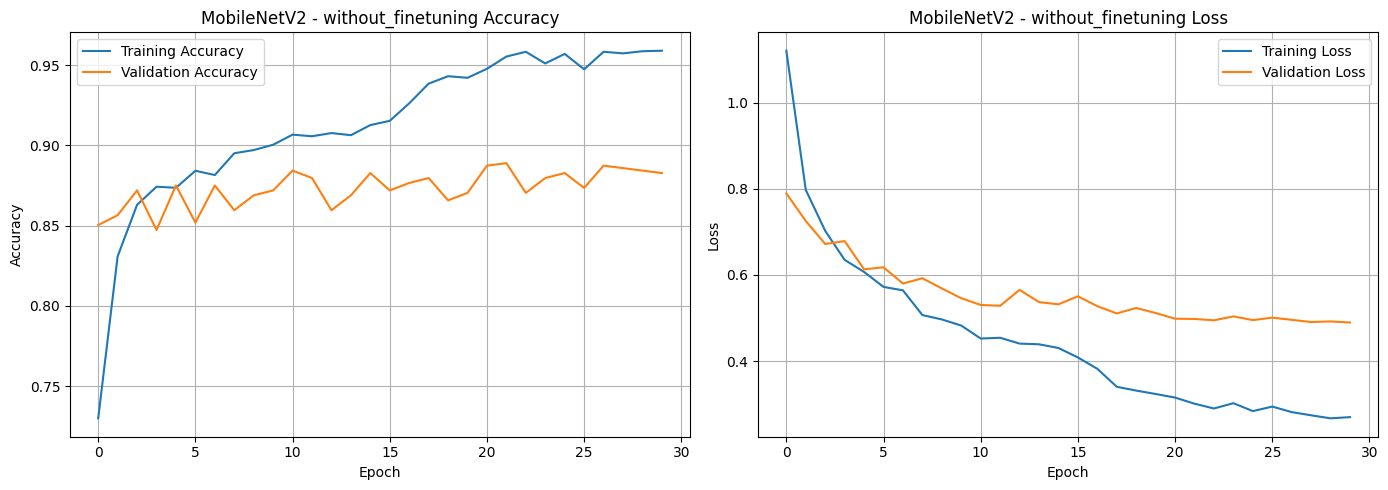


MobileNetV2 - without_finetuning
21/21 ━━━━━━━━━━━━━━━━━━━━ 4s 126ms/step

Classification Report:

              precision    recall  f1-score   support

       daisy       0.91      0.92      0.91       115
   dandelion       0.94      0.91      0.92       158
        rose       0.89      0.86      0.87       117
   sunflower       0.91      0.93      0.92       110
       tulip       0.88      0.91      0.89       148

    accuracy                           0.90       648
   macro avg       0.90      0.90      0.90       648
weighted avg       0.90      0.90      0.90       648



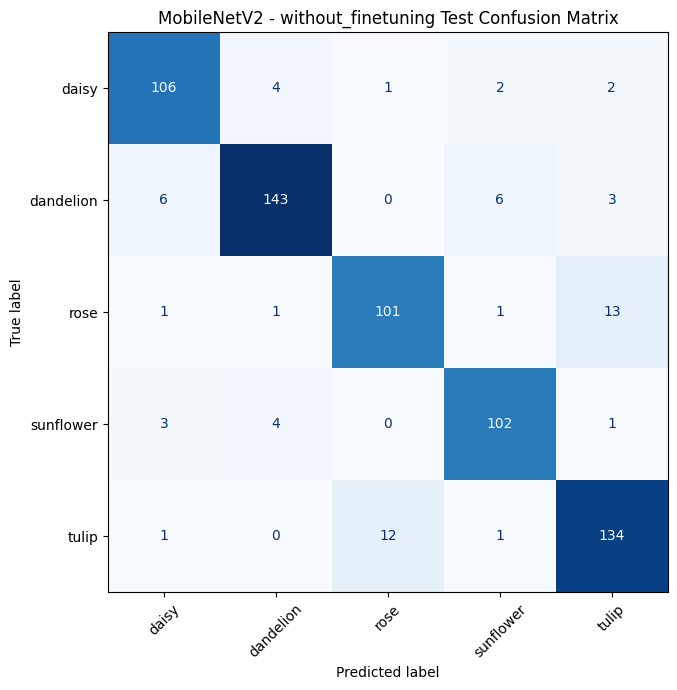

Test Accuracy: 0.9043
Test Loss: 0.4469

WITH FINE-TUNING
Epoch 1/30
94/95 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - accuracy: 0.9514 - loss: 0.2677
Epoch 1: val_loss improved from None to 0.48881, saving model to /content/MobileNetV2_with_finetuning.weights.h5

Epoch 1: finished saving model to /content/MobileNetV2_with_finetuning.weights.h5
95/95 ━━━━━━━━━━━━━━━━━━━━ 20s 105ms/step - accuracy: 0.9507 - loss: 0.2740 - val_accuracy: 0.8873 - val_loss: 0.4888 - learning_rate: 1.0000e-05
Epoch 2/30
94/95 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - accuracy: 0.9622 - loss: 0.2519
Epoch 2: val_loss improved from 0.48881 to 0.47924, saving model to /content/MobileNetV2_with_finetuning.weights.h5

Epoch 2: finished saving model to /content/MobileNetV2_with_finetuning.weights.h5
95/95 ━━━━━━━━━━━━━━━━━━━━ 18s 93ms/step - accuracy: 0.9623 - loss: 0.2589 - val_accuracy: 0.8935 - val_loss: 0.4792 - learning_rate: 1.0000e-05
Epoch 3/30
94/95 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - accuracy: 0.9613 - loss: 0.2612
E

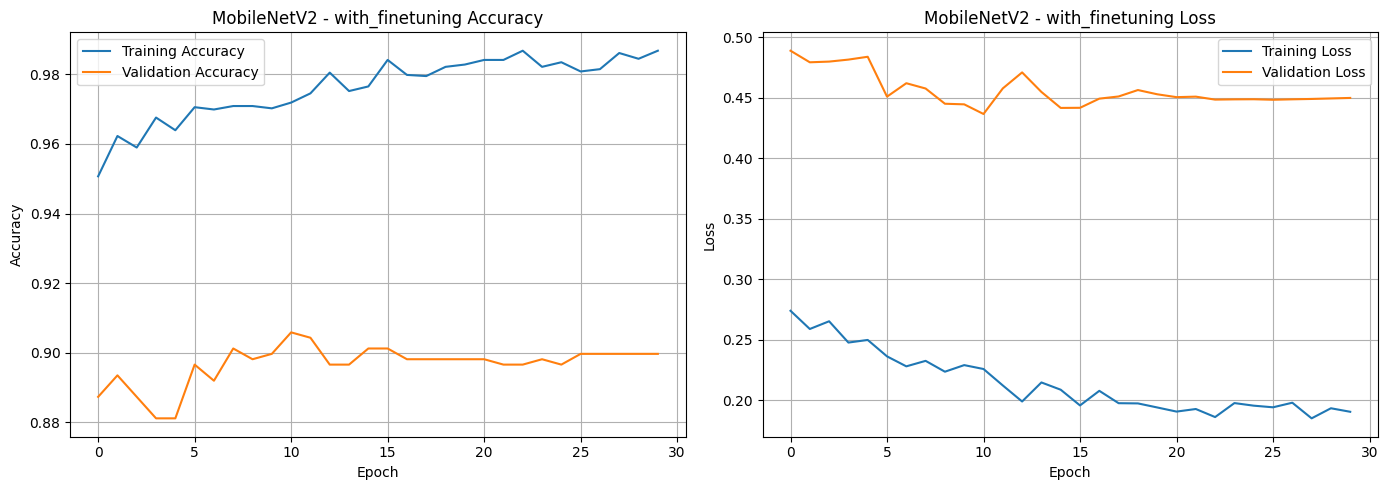


MobileNetV2 - with_finetuning
21/21 ━━━━━━━━━━━━━━━━━━━━ 3s 105ms/step

Classification Report:

              precision    recall  f1-score   support

       daisy       0.91      0.93      0.92       115
   dandelion       0.94      0.93      0.94       158
        rose       0.93      0.83      0.88       117
   sunflower       0.93      0.94      0.93       110
       tulip       0.86      0.93      0.90       148

    accuracy                           0.91       648
   macro avg       0.92      0.91      0.91       648
weighted avg       0.91      0.91      0.91       648



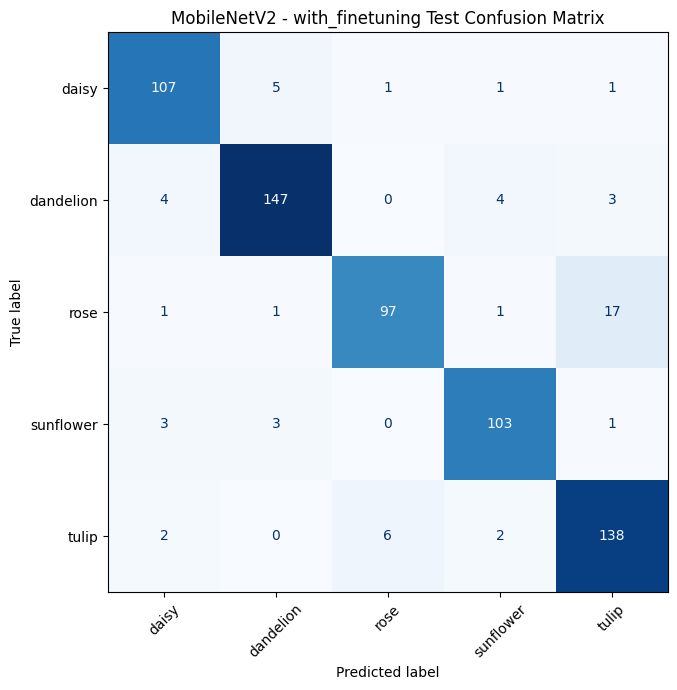

Test Accuracy: 0.9136
Test Loss: 0.4516



######################################################################
STARTING MODEL: ResNet50
######################################################################

WITHOUT FINE-TUNING
Epoch 1/30
95/95 ━━━━━━━━━━━━━━━━━━━━ 0s 157ms/step - accuracy: 0.6656 - loss: 1.4206
Epoch 1: val_loss improved from None to 0.72145, saving model to /content/ResNet50_without_finetuning.weights.h5

Epoch 1: finished saving model to /content/ResNet50_without_finetuning.weights.h5
95/95 ━━━━━━━━━━━━━━━━━━━━ 32s 223ms/step - accuracy: 0.7564 - loss: 1.1163 - val_accuracy: 0.8781 - val_loss: 0.7215 - learning_rate: 0.0010
Epoch 2/30
95/95 ━━━━━━━━━━━━━━━━━━━━ 0s 162ms/step - accuracy: 0.8543 - loss: 0.7763
Epoch 2: val_loss improved from 0.72145 to 0.64347, saving model to /content/ResNet50_without_finetuning.weights.h5

Epoch 2: finished saving model to /content/ResNet50_without_finetuning.weights.h5
95/95 ━━━━━━━━━━━━━━━━━━━━ 23s 204ms/step - accuracy: 0.8491

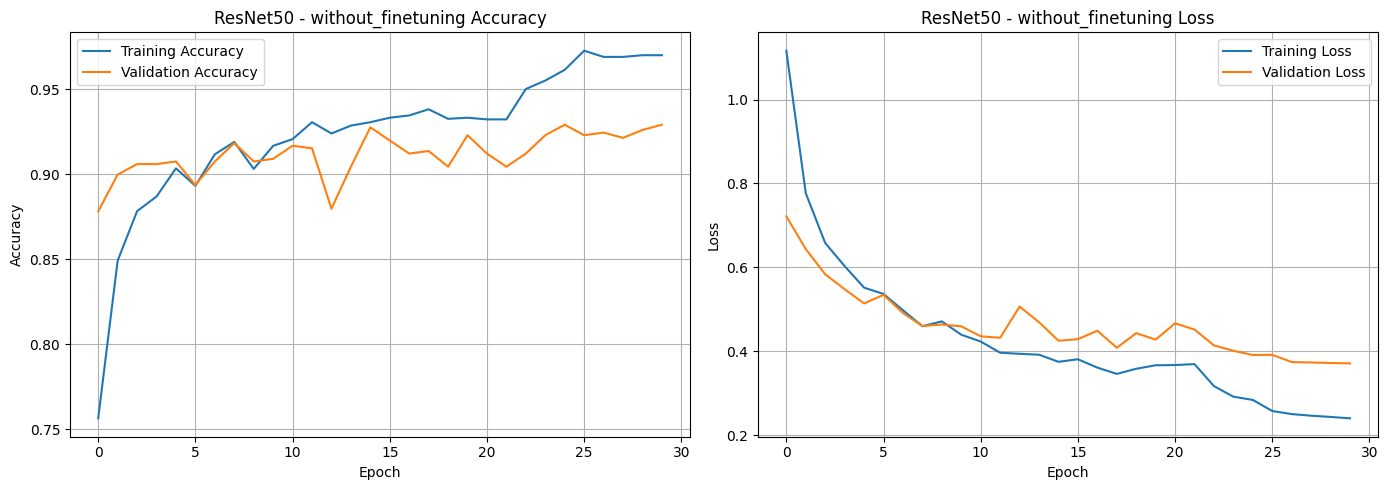


ResNet50 - without_finetuning
21/21 ━━━━━━━━━━━━━━━━━━━━ 7s 216ms/step

Classification Report:

              precision    recall  f1-score   support

       daisy       0.95      0.92      0.94       115
   dandelion       0.93      0.95      0.94       158
        rose       0.89      0.90      0.89       117
   sunflower       0.96      0.93      0.94       110
       tulip       0.89      0.91      0.90       148

    accuracy                           0.92       648
   macro avg       0.93      0.92      0.92       648
weighted avg       0.92      0.92      0.92       648



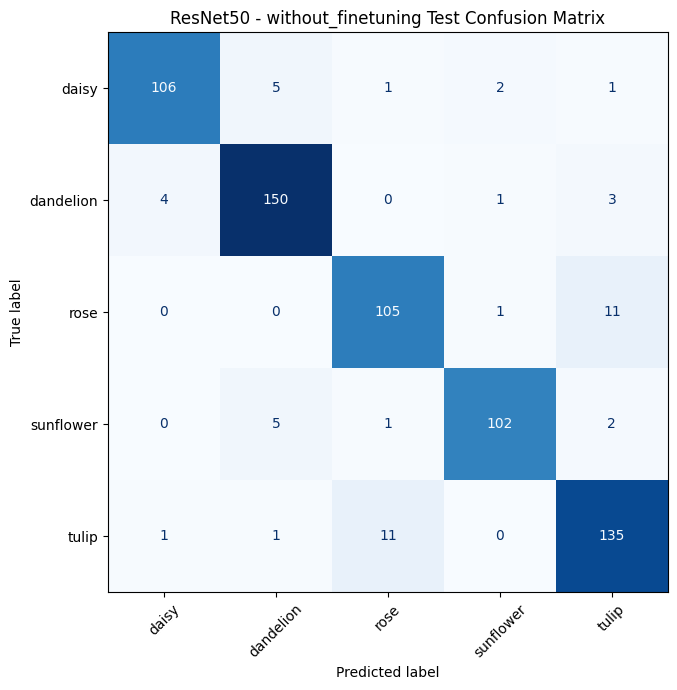

Test Accuracy: 0.9228
Test Loss: 0.4005

WITH FINE-TUNING
Epoch 1/30
95/95 ━━━━━━━━━━━━━━━━━━━━ 0s 203ms/step - accuracy: 0.9677 - loss: 0.2390
Epoch 1: val_loss improved from None to 0.36809, saving model to /content/ResNet50_with_finetuning.weights.h5

Epoch 1: finished saving model to /content/ResNet50_with_finetuning.weights.h5
95/95 ━━━━━━━━━━━━━━━━━━━━ 38s 267ms/step - accuracy: 0.9715 - loss: 0.2293 - val_accuracy: 0.9275 - val_loss: 0.3681 - learning_rate: 1.0000e-05
Epoch 2/30
95/95 ━━━━━━━━━━━━━━━━━━━━ 0s 195ms/step - accuracy: 0.9734 - loss: 0.2319
Epoch 2: val_loss improved from 0.36809 to 0.36242, saving model to /content/ResNet50_with_finetuning.weights.h5

Epoch 2: finished saving model to /content/ResNet50_with_finetuning.weights.h5
95/95 ━━━━━━━━━━━━━━━━━━━━ 28s 237ms/step - accuracy: 0.9735 - loss: 0.2282 - val_accuracy: 0.9182 - val_loss: 0.3624 - learning_rate: 1.0000e-05
Epoch 3/30
95/95 ━━━━━━━━━━━━━━━━━━━━ 0s 192ms/step - accuracy: 0.9791 - loss: 0.2059
Epoch 3: 

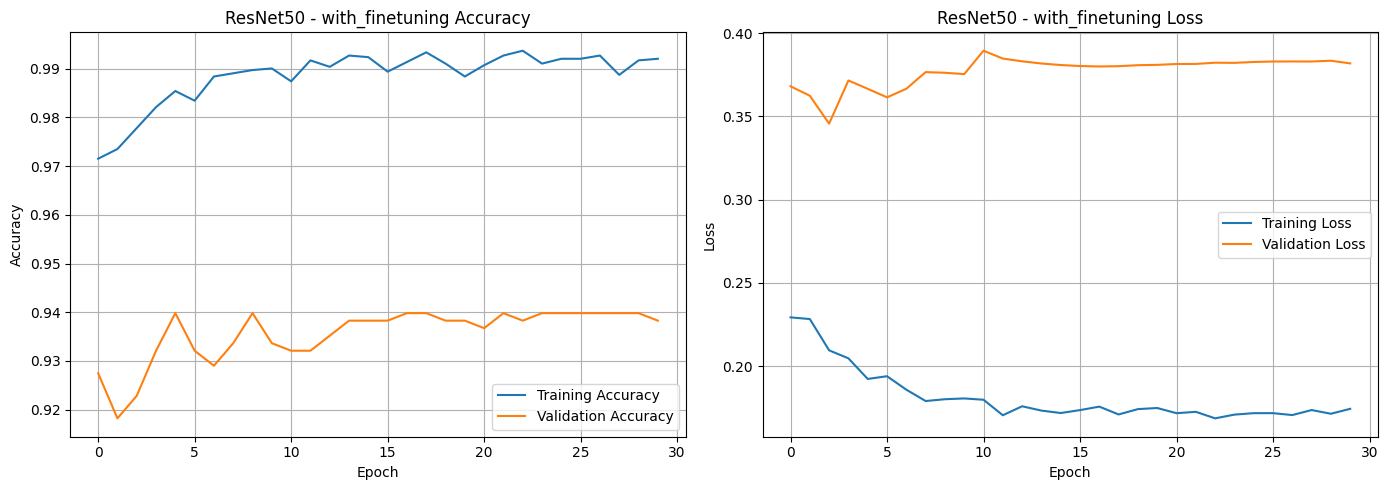


ResNet50 - with_finetuning
21/21 ━━━━━━━━━━━━━━━━━━━━ 7s 244ms/step

Classification Report:

              precision    recall  f1-score   support

       daisy       0.89      0.95      0.92       115
   dandelion       0.93      0.94      0.93       158
        rose       0.91      0.90      0.91       117
   sunflower       0.97      0.92      0.94       110
       tulip       0.92      0.91      0.92       148

    accuracy                           0.92       648
   macro avg       0.93      0.92      0.92       648
weighted avg       0.93      0.92      0.92       648



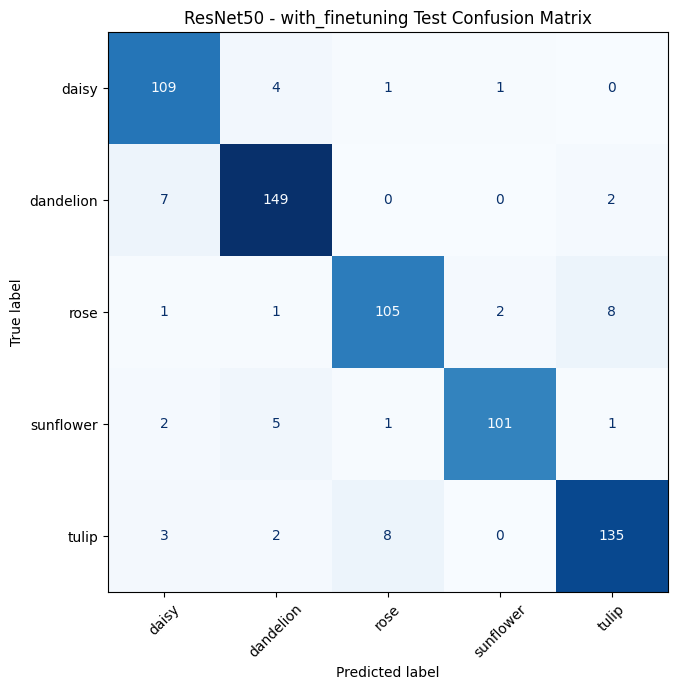

Test Accuracy: 0.9244
Test Loss: 0.4116



######################################################################
STARTING MODEL: EfficientNetB0
######################################################################

WITHOUT FINE-TUNING
Epoch 1/30
94/95 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step - accuracy: 0.7033 - loss: 1.1987
Epoch 1: val_loss improved from None to 0.65755, saving model to /content/EfficientNetB0_without_finetuning.weights.h5

Epoch 1: finished saving model to /content/EfficientNetB0_without_finetuning.weights.h5
95/95 ━━━━━━━━━━━━━━━━━━━━ 27s 137ms/step - accuracy: 0.7925 - loss: 0.9695 - val_accuracy: 0.8951 - val_loss: 0.6575 - learning_rate: 0.0010
Epoch 2/30
94/95 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step - accuracy: 0.8728 - loss: 0.7030
Epoch 2: val_loss improved from 0.65755 to 0.58415, saving model to /content/EfficientNetB0_without_finetuning.weights.h5

Epoch 2: finished saving model to /content/EfficientNetB0_without_finetuning.weights.h5
95/95 ━━━━━━━━━━━━━━━━━━━━ 16s 1

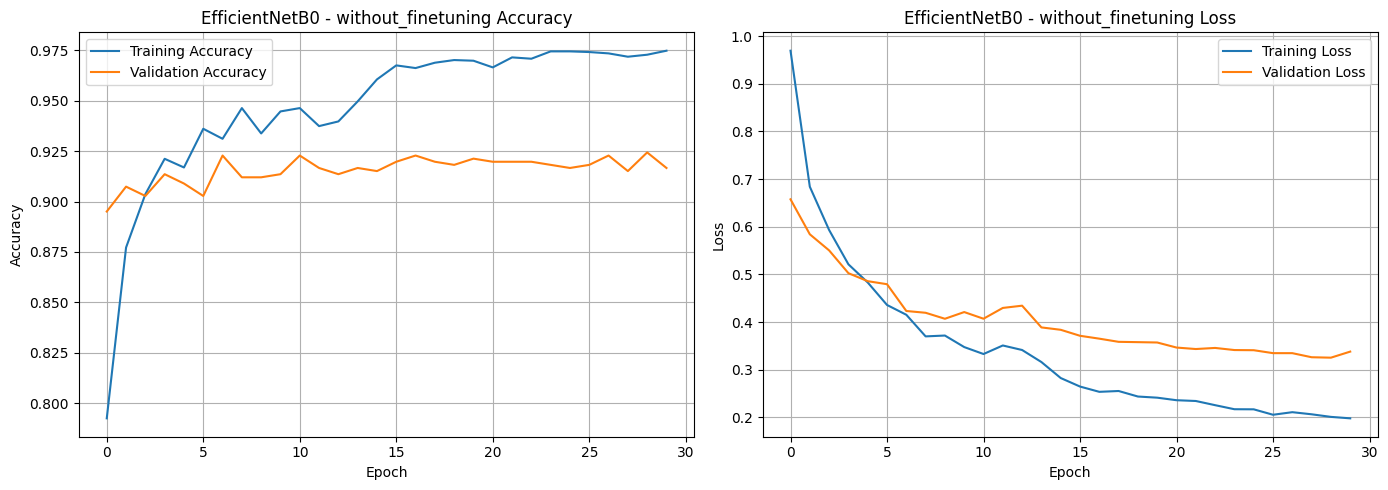


EfficientNetB0 - without_finetuning
21/21 ━━━━━━━━━━━━━━━━━━━━ 6s 171ms/step

Classification Report:

              precision    recall  f1-score   support

       daisy       0.94      0.92      0.93       115
   dandelion       0.94      0.94      0.94       158
        rose       0.91      0.92      0.92       117
   sunflower       0.95      0.97      0.96       110
       tulip       0.92      0.91      0.92       148

    accuracy                           0.93       648
   macro avg       0.93      0.93      0.93       648
weighted avg       0.93      0.93      0.93       648



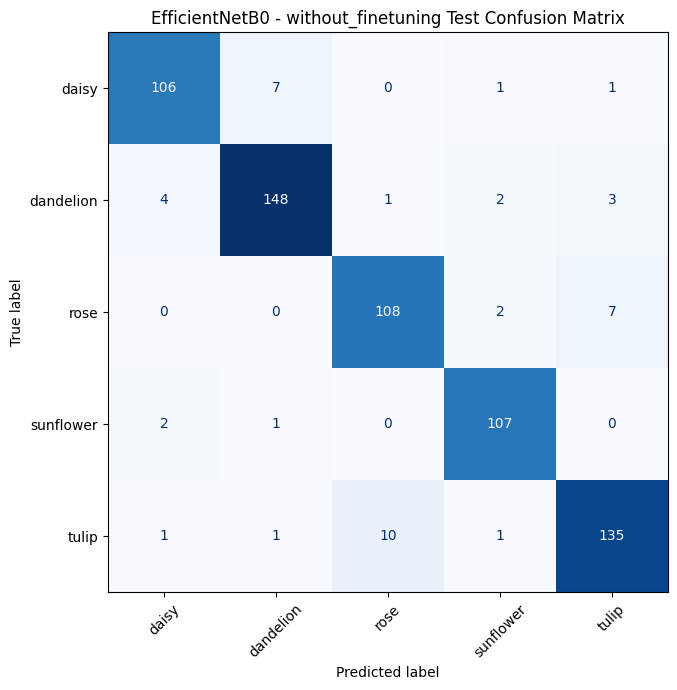

Test Accuracy: 0.9321
Test Loss: 0.3197

WITH FINE-TUNING
Epoch 1/30
95/95 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step - accuracy: 0.9751 - loss: 0.1958
Epoch 1: val_loss improved from None to 0.32893, saving model to /content/EfficientNetB0_with_finetuning.weights.h5

Epoch 1: finished saving model to /content/EfficientNetB0_with_finetuning.weights.h5
95/95 ━━━━━━━━━━━━━━━━━━━━ 30s 154ms/step - accuracy: 0.9758 - loss: 0.1942 - val_accuracy: 0.9198 - val_loss: 0.3289 - learning_rate: 1.0000e-05
Epoch 2/30
95/95 ━━━━━━━━━━━━━━━━━━━━ 0s 98ms/step - accuracy: 0.9811 - loss: 0.1803
Epoch 2: val_loss improved from 0.32893 to 0.32631, saving model to /content/EfficientNetB0_with_finetuning.weights.h5

Epoch 2: finished saving model to /content/EfficientNetB0_with_finetuning.weights.h5
95/95 ━━━━━━━━━━━━━━━━━━━━ 15s 123ms/step - accuracy: 0.9821 - loss: 0.1823 - val_accuracy: 0.9198 - val_loss: 0.3263 - learning_rate: 1.0000e-05
Epoch 3/30
95/95 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step - accuracy: 0.9774 - l

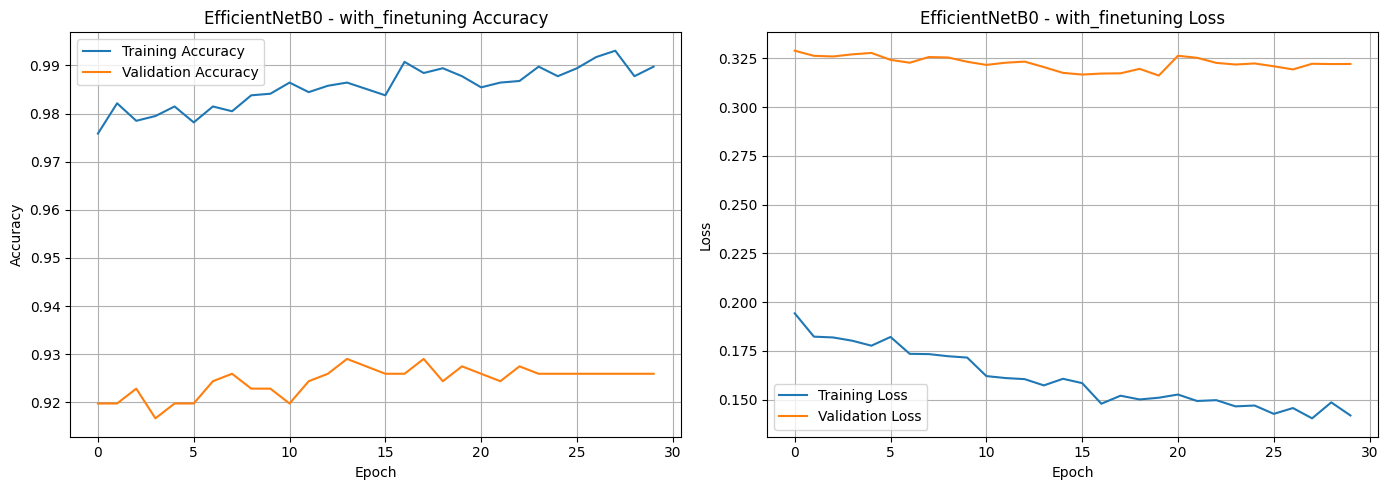


EfficientNetB0 - with_finetuning
21/21 ━━━━━━━━━━━━━━━━━━━━ 6s 177ms/step

Classification Report:

              precision    recall  f1-score   support

       daisy       0.94      0.91      0.93       115
   dandelion       0.95      0.93      0.94       158
        rose       0.89      0.92      0.91       117
   sunflower       0.95      0.96      0.95       110
       tulip       0.91      0.91      0.91       148

    accuracy                           0.93       648
   macro avg       0.93      0.93      0.93       648
weighted avg       0.93      0.93      0.93       648



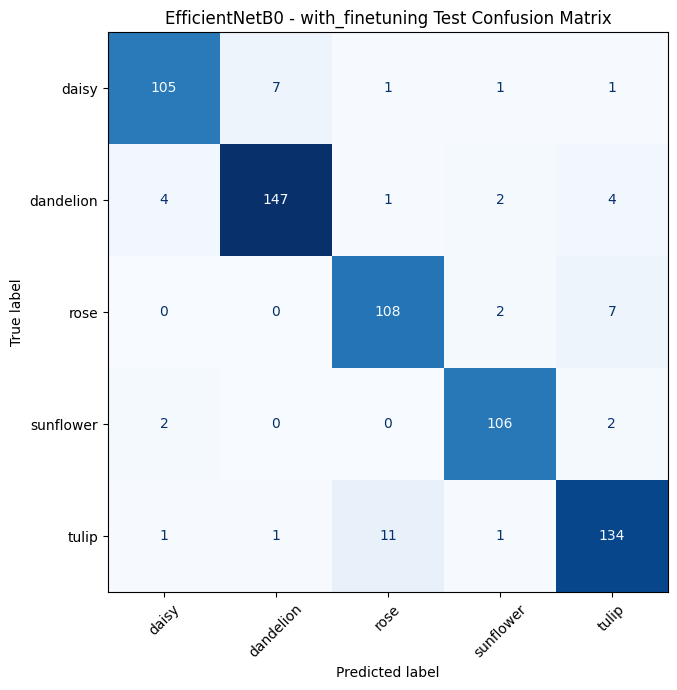

Test Accuracy: 0.9259
Test Loss: 0.323

ALL SIX EXPERIMENTS COMPLETED!


In [ ]:

all_results = []

for model_name in model_configs:

    print("\n\n")
    print("#" * 70)
    print("STARTING MODEL:", model_name)
    print("#" * 70)

    tf.keras.backend.clear_session()
    gc.collect()

    model, base_model = build_model(model_name)

    # =================================
    # EXPERIMENT A: WITHOUT FINE-TUNING
    # =================================

    print("\nWITHOUT FINE-TUNING")

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    callbacks, checkpoint = get_callbacks(
        model_name, "without_finetuning"
    )

    history_frozen = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        callbacks=callbacks,
        verbose=1
    )

    model.load_weights(checkpoint)

    plot_history(
        history_frozen,
        model_name,
        "without_finetuning"
    )

    result = evaluate_model(
        model,
        model_name,
        "without_finetuning"
    )

    all_results.append(result)

    # =================================
    # EXPERIMENT B: WITH FINE-TUNING
    # =================================

    print("\nWITH FINE-TUNING")

    base_model.trainable = True

    # Freeze earlier layers
    for layer in base_model.layers[:-30]:
        layer.trainable = False

    # Keep Batch Normalization frozen
    for layer in base_model.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=0.00001
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    callbacks, checkpoint = get_callbacks(
        model_name, "with_finetuning"
    )

    history_finetuned = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        callbacks=callbacks,
        verbose=1
    )

    model.load_weights(checkpoint)

    plot_history(
        history_finetuned,
        model_name,
        "with_finetuning"
    )

    result = evaluate_model(
        model,
        model_name,
        "with_finetuning"
    )

    all_results.append(result)

    del model, base_model
    gc.collect()

print("\nALL SIX EXPERIMENTS COMPLETED!")


FINAL MODEL COMPARISON


,Model,Mode,Test Accuracy,Test Loss
0,MobileNetV2,without_finetuning,0.908951,0.451138
1,MobileNetV2,with_finetuning,0.921296,0.438868
2,ResNet50,without_finetuning,0.927469,0.405958
3,ResNet50,with_finetuning,0.918210,0.403023
4,EfficientNetB0,without_finetuning,0.925926,0.320529
5,EfficientNetB0,with_finetuning,0.929012,0.324056


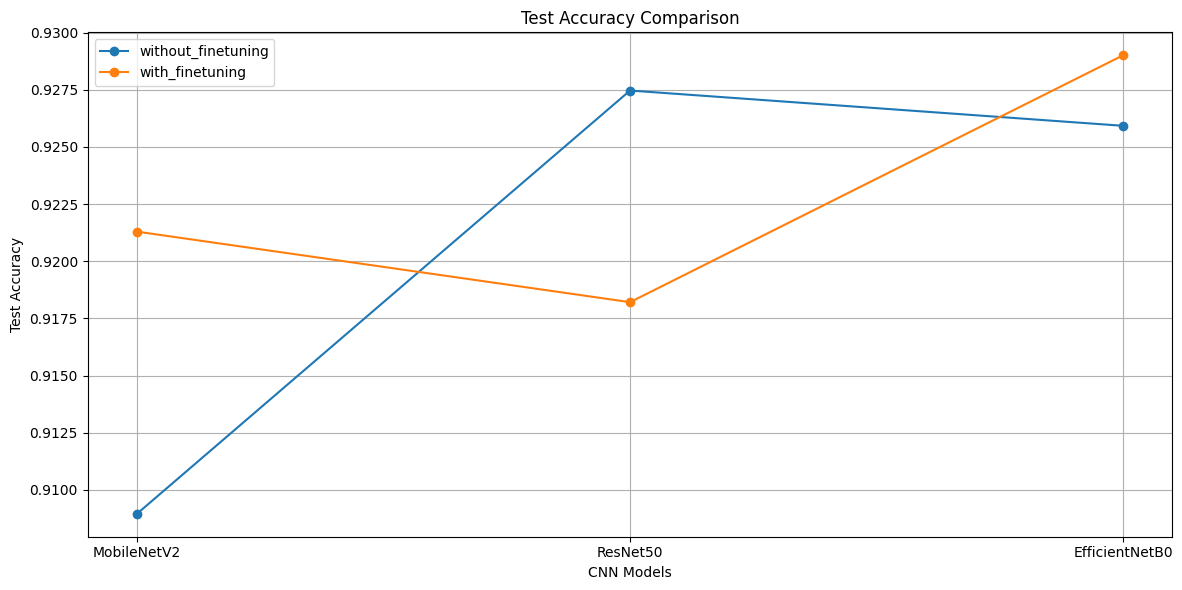

In [ ]:

results_df = pd.DataFrame(all_results)

print("FINAL MODEL COMPARISON")
display(results_df)

results_df.to_csv(
    "/content/results/final_model_comparison.csv",
    index=False
)

plt.figure(figsize=(12, 6))

for mode in results_df["Mode"].unique():

    subset = results_df[
        results_df["Mode"] == mode
    ]

    plt.plot(
        subset["Model"],
        subset["Test Accuracy"],
        marker="o",
        label=mode
    )

plt.title("Test Accuracy Comparison")
plt.xlabel("CNN Models")
plt.ylabel("Test Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    "/content/results/final_accuracy_comparison.png"
)

plt.show()
